<a href="https://colab.research.google.com/github/thegurdian/ML/blob/main/real_diabetes_paper_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

Dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


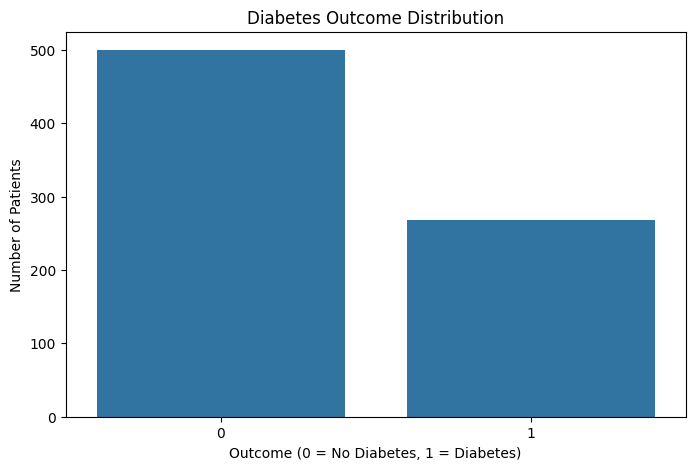


Missing values after zero replacement:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Features shape: (768, 8)
Target shape: (768,)

Training samples: 614
Testing samples: 154

Training outcome distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Testing outcome distribution:
Outcome
0    100
1     54
Name: count, dtype: int64

Training Median Values:


,0
Pregnancies,3.0000
Glucose,117.0000
BloodPressure,72.0000
SkinThickness,29.0000
Insulin,125.0000
BMI,32.4000
DiabetesPedigreeFunction,0.3825
Age,29.0000



Training missing values: 0
Testing missing values: 0


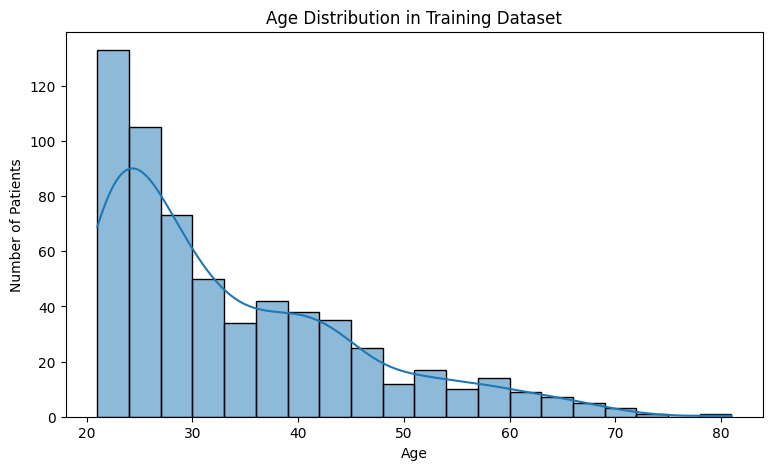

Minimum Age: 21
Maximum Age: 81
Mean Age: 33.36644951140065
Median Age: 29.0

Training Age Group Distribution:
Age_Group
Age_21_30      328
Age_31_40      130
Age_41_50       89
Age_51_plus     67
Name: count, dtype: int64

Testing Age Group Distribution:
Age_Group
Age_21_30      89
Age_31_40      27
Age_41_50      24
Age_51_plus    14
Name: count, dtype: int64

Age Group vs Diabetes Distribution:


,Non_Diabetic,Diabetic
Age_Group,,
Age_21_30,256,72
Age_31_40,72,58
Age_41_50,38,51
Age_51_plus,34,33


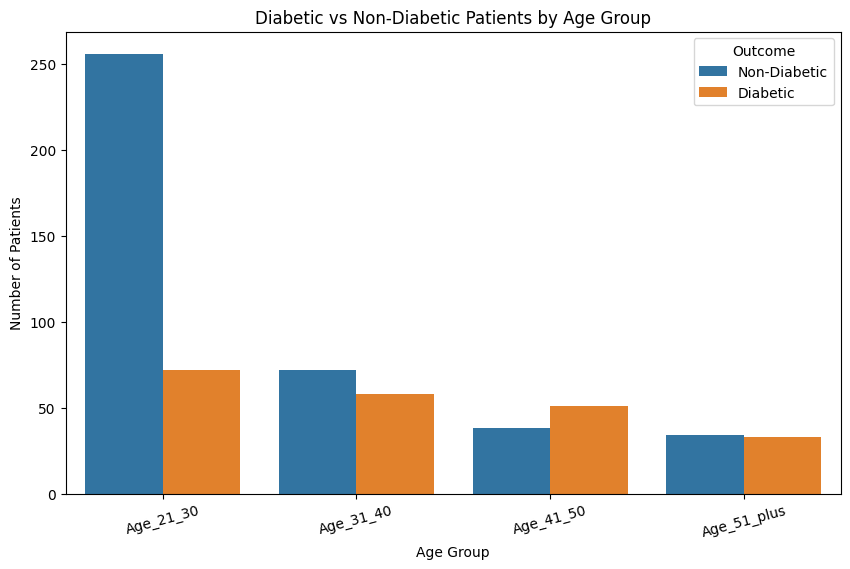


Age_21_30
Total Samples: 328
Non-Diabetic: 256
Diabetic: 72

Age_31_40
Total Samples: 130
Non-Diabetic: 72
Diabetic: 58

Age_41_50
Total Samples: 89
Non-Diabetic: 38
Diabetic: 51

Age_51_plus
Total Samples: 67
Non-Diabetic: 34
Diabetic: 33

STEP 1-3 COMPLETED SUCCESSFULLY
Training Shape: (614, 9)
Testing Shape: (154, 9)
Number of Age Groups: 4

Ready for Step 4: Bagging Classifier Training


In [1]:

# ============================================================
# AGE-SEGMENTED BAGGING DIABETES PREDICTION
# PIMA INDIANS DIABETES DATASET
# STEPS 1-3: LOADING, PREPROCESSING, AGE SEGMENTATION
# ============================================================


# =========================
# STEP 1: IMPORT LIBRARIES
# =========================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")


# =========================
# STEP 2: LOAD DATASET
# =========================

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(url, names=columns)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


# =========================
# STEP 3: DATA EXPLORATION
# =========================

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nOutcome Distribution:")
print(df["Outcome"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Outcome")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.show()


# =========================
# STEP 4: ZERO TO NaN
# =========================

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("\nMissing values after zero replacement:")
print(df.isnull().sum())


# =========================
# STEP 5: FEATURE AND TARGET
# =========================

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)


# =========================
# STEP 6: TRAIN TEST SPLIT
# =========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining outcome distribution:")
print(y_train.value_counts())

print("\nTesting outcome distribution:")
print(y_test.value_counts())


# =========================
# STEP 7: OVERALL MEDIAN IMPUTATION
# =========================

# Calculate medians using training data ONLY

training_medians = X_train.median()

print("\nTraining Median Values:")
display(training_medians)

# Apply the same medians to training and testing data

X_train_imputed = X_train.fillna(training_medians)
X_test_imputed = X_test.fillna(training_medians)

print("\nTraining missing values:",
      X_train_imputed.isnull().sum().sum())

print("Testing missing values:",
      X_test_imputed.isnull().sum().sum())


# =========================
# STEP 8: AGE DISTRIBUTION
# =========================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=X_train_imputed,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Age Distribution in Training Dataset")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

print("Minimum Age:", X_train_imputed["Age"].min())
print("Maximum Age:", X_train_imputed["Age"].max())
print("Mean Age:", X_train_imputed["Age"].mean())
print("Median Age:", X_train_imputed["Age"].median())


# =========================
# STEP 9: DEFINE AGE GROUPS
# =========================

age_bins = [0, 30, 40, 50, np.inf]

age_labels = [
    "Age_21_30",
    "Age_31_40",
    "Age_41_50",
    "Age_51_plus"
]

# Apply identical boundaries to train and test

X_train_imputed["Age_Group"] = pd.cut(
    X_train_imputed["Age"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

X_test_imputed["Age_Group"] = pd.cut(
    X_test_imputed["Age"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

print("\nTraining Age Group Distribution:")
print(X_train_imputed["Age_Group"].value_counts().sort_index())

print("\nTesting Age Group Distribution:")
print(X_test_imputed["Age_Group"].value_counts().sort_index())


# =========================
# STEP 10: AGE GROUP OUTCOME ANALYSIS
# =========================

train_analysis = X_train_imputed.copy()

train_analysis["Outcome"] = y_train

age_outcome_table = pd.crosstab(
    train_analysis["Age_Group"],
    train_analysis["Outcome"]
)

age_outcome_table.columns = [
    "Non_Diabetic",
    "Diabetic"
]

print("\nAge Group vs Diabetes Distribution:")
display(age_outcome_table)


# =========================
# STEP 11: VISUALIZATION
# =========================

plt.figure(figsize=(10, 6))

sns.countplot(
    data=train_analysis,
    x="Age_Group",
    hue="Outcome"
)

plt.title("Diabetic vs Non-Diabetic Patients by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.xticks(rotation=15)

plt.legend(
    title="Outcome",
    labels=["Non-Diabetic", "Diabetic"]
)

plt.show()


# =========================
# STEP 12: CREATE SEPARATE DATASETS
# =========================

age_group_data = {}

for group in age_labels:

    train_mask = X_train_imputed["Age_Group"] == group

    X_group = X_train_imputed.loc[
        train_mask
    ].drop(columns=["Age_Group"])

    y_group = y_train.loc[train_mask]

    age_group_data[group] = {
        "X": X_group,
        "y": y_group
    }

    print("\n==============================")
    print(group)
    print("==============================")

    print("Total Samples:", len(X_group))
    print("Non-Diabetic:", (y_group == 0).sum())
    print("Diabetic:", (y_group == 1).sum())


# =========================
# FINAL VERIFICATION
# =========================

print("\n================================")
print("STEP 1-3 COMPLETED SUCCESSFULLY")
print("================================")

print("Training Shape:", X_train_imputed.shape)
print("Testing Shape:", X_test_imputed.shape)

print("Number of Age Groups:", len(age_group_data))

print("\nReady for Step 4: Bagging Classifier Training")


Import and initialize Bagging

In [2]:

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Store four independent models
bagging_models = {}

# Bagging parameters
n_estimators = 100
max_samples = 0.80

print("Bagging configuration initialized!")


Bagging configuration initialized!


Train all four models

In [3]:

for group in age_labels:

    print("\nTraining:", group)

    # Get age-specific training data
    X_group = age_group_data[group]["X"]
    y_group = age_group_data[group]["y"]

    # Create base Decision Tree
    base_tree = DecisionTreeClassifier(
        random_state=42
    )

    # Create Bagging Classifier
    bagging_model = BaggingClassifier(
        estimator=base_tree,
        n_estimators=n_estimators,
        max_samples=max_samples,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    # Train model
    bagging_model.fit(X_group, y_group)

    # Save model
    bagging_models[group] = bagging_model

    print("Training completed!")
    print("Samples:", len(X_group))
    print("Number of trees:", n_estimators)

print("\nAll four Bagging models trained successfully!")



Training: Age_21_30
Training completed!
Samples: 328
Number of trees: 100

Training: Age_31_40
Training completed!
Samples: 130
Number of trees: 100

Training: Age_41_50
Training completed!
Samples: 89
Number of trees: 100

Training: Age_51_plus
Training completed!
Samples: 67
Number of trees: 100

All four Bagging models trained successfully!


Check training performance

In [5]:
from sklearn.metrics import accuracy_score

for group in age_labels:

    X_group = age_group_data[group]["X"]
    y_group = age_group_data[group]["y"]

    model = bagging_models[group]

    train_predictions = model.predict(X_group)

    accuracy = accuracy_score(
        y_group,
        train_predictions
    )

    print("\n", group)
    print("Training Accuracy:", round(accuracy, 4))


 Age_21_30
Training Accuracy: 0.997

 Age_31_40
Training Accuracy: 1.0

 Age_41_50
Training Accuracy: 1.0

 Age_51_plus
Training Accuracy: 1.0


Generate predictions for test patients

In [6]:

# Store predictions
test_predictions = pd.Series(
    index=X_test_imputed.index,
    dtype="int64"
)

test_probabilities = pd.Series(
    index=X_test_imputed.index,
    dtype="float64"
)

for group in age_labels:

    # Select patients belonging to this age group
    test_mask = X_test_imputed["Age_Group"] == group

    # Extract test features
    X_group_test = X_test_imputed.loc[
        test_mask
    ].drop(columns=["Age_Group"])

    if len(X_group_test) == 0:
        continue

    # Select corresponding Bagging model
    model = bagging_models[group]

    # Predict class
    predictions = model.predict(X_group_test)

    # Predict diabetes probability
    probabilities = model.predict_proba(
        X_group_test
    )[:, 1]

    # Save predictions
    test_predictions.loc[test_mask] = predictions

    test_probabilities.loc[test_mask] = probabilities


print("All test predictions generated!")

print("\nPrediction distribution:")
print(test_predictions.value_counts())

print("\nProbability preview:")
display(test_probabilities.head())


All test predictions generated!

Prediction distribution:
0.0    100
1.0     54
Name: count, dtype: int64

Probability preview:


,0
44,0.72
672,0.17
700,0.04
630,0.24
81,0.12


Verify predictions

In [7]:

# Combine actual and predicted values

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": test_predictions,
    "Diabetes_Probability": test_probabilities,
    "Age": X_test_imputed["Age"],
    "Age_Group": X_test_imputed["Age_Group"]
})

display(results.head(15))

print("Missing predictions:", test_predictions.isnull().sum())


,Actual,Predicted,Diabetes_Probability,Age,Age_Group
44,0,1.0,0.72,40,Age_31_40
672,0,0.0,0.17,47,Age_41_50
700,0,0.0,0.04,26,Age_21_30
630,1,0.0,0.24,34,Age_31_40
81,0,0.0,0.12,22,Age_21_30
389,0,0.0,0.45,28,Age_21_30
387,1,1.0,0.51,45,Age_41_50
408,1,1.0,0.70,39,Age_31_40
163,0,0.0,0.00,21,Age_21_30
335,0,1.0,0.95,26,Age_21_30


Missing predictions: 0


Libraries imported successfully!

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Outcome distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Missing values:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Training shape: (614, 8)
Testing shape: (154, 8)

Training missing values: 0
Testing missing values: 0

Training age distribution:
Age
Age_21_30      328
Age_31_40      130
Age_41_50       89
Age_51_plus     67
Name: count, dtype: int64

Testing age distribution:
Age
Age_21_30      89
Age_31_40      27
Age_41_50      24
Age_51_plus    14
Name: count, dtype: int64

Age group distribution:


,Non_Diabetic,Diabetic
Age_Group,,
Age_21_30,256,72
Age_31_40,72,58
Age_41_50,38,51
Age_51_plus,34,33


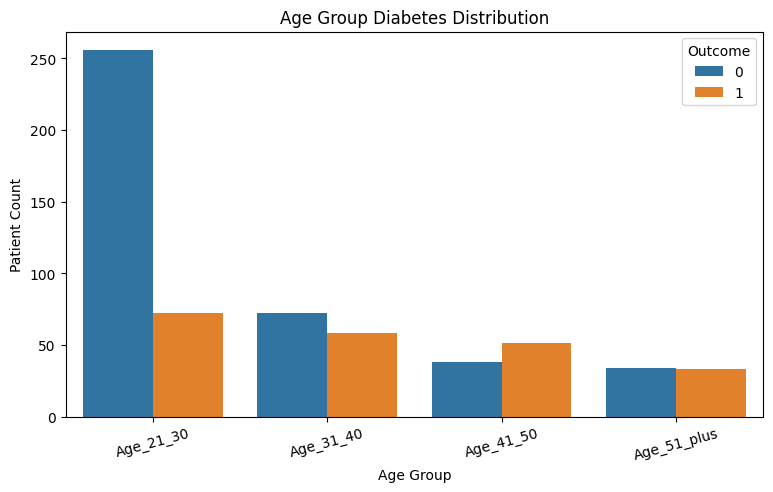


Bagging configuration ready!

========== FOLD 1 ==========
Fold completed!

========== FOLD 2 ==========
Fold completed!

========== FOLD 3 ==========
Fold completed!

========== FOLD 4 ==========
Fold completed!

========== FOLD 5 ==========
Fold completed!

All cross-validation folds completed!

FOLD-WISE PERFORMANCE:


Model,Model A,Model B,Model C
Fold,,,
1,0.6111,0.6582,0.6301
2,0.5429,0.5897,0.5946
3,0.6567,0.6757,0.6471
4,0.6316,0.6588,0.6585
5,0.6301,0.6905,0.6750



CROSS VALIDATION SUMMARY:


Accuracy         Precision          Recall              F1          \
            mean     std      mean     std    mean     std    mean     std   
Model                                                                        
Model A   0.7752  0.0260    0.7696  0.0846  0.5142  0.0455  0.6145  0.0432   
Model B   0.7753  0.0246    0.7086  0.0602  0.6125  0.0605  0.6546  0.0386   
Model C   0.7801  0.0180    0.7518  0.0769  0.5658  0.0645  0.6411  0.0307   

        Specificity         ROC_AUC          
               mean     std    mean     std  
Model                                        
Model A      0.9150  0.0347  0.8207  0.0250  
Model B      0.8625  0.0395  0.8209  0.0344  
Model C      0.8950  0.0447  0.8272  0.0273


OUT-OF-FOLD PERFORMANCE:


,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC
Model A - Global,0.7752,0.7639,0.5140,0.6145,0.9150,0.8198
Model B - Age Segmented,0.7752,0.7043,0.6121,0.6550,0.8625,0.8156
Model C - Hybrid,0.7801,0.7423,0.5654,0.6419,0.8950,0.8235


... (2 outputs left out)


========== TRAINING PERFORMANCE ==========


,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC
Model A - Global,0.7948,0.7821,0.5701,0.6595,0.9150,0.8835
Model B - Age Segmented,0.8420,0.8343,0.6822,0.7506,0.9275,0.9229
Model C - Hybrid,0.8208,0.8133,0.6308,0.7105,0.9225,0.9104



========== OVERFITTING ANALYSIS ==========


,Train Accuracy,Test Accuracy,Train F1,Test F1,Train ROC_AUC,Test ROC_AUC,Accuracy Gap,F1 Gap
Model A - Global,0.7948,0.7273,0.6595,0.5532,0.8835,0.8046,0.0675,0.1063
Model B - Age Segmented,0.8420,0.7468,0.7506,0.6061,0.9229,0.7952,0.0953,0.1446
Model C - Hybrid,0.8208,0.7273,0.7105,0.5714,0.9104,0.8009,0.0936,0.1391


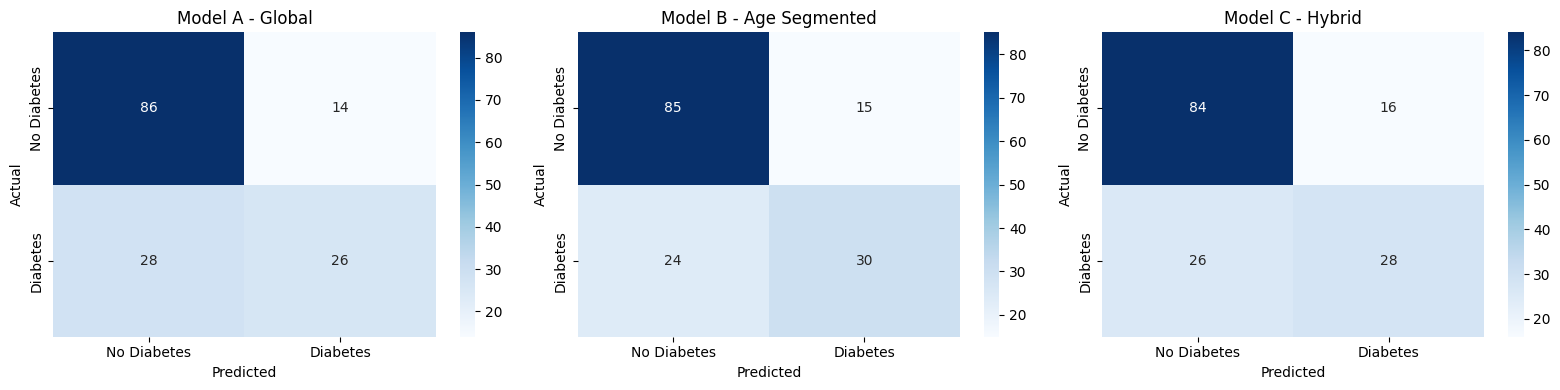

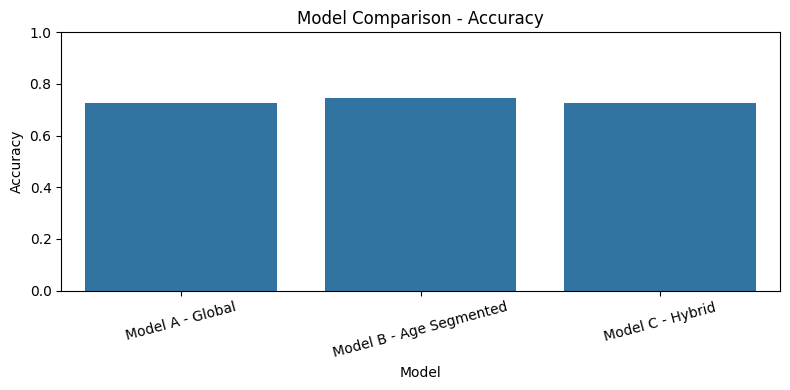

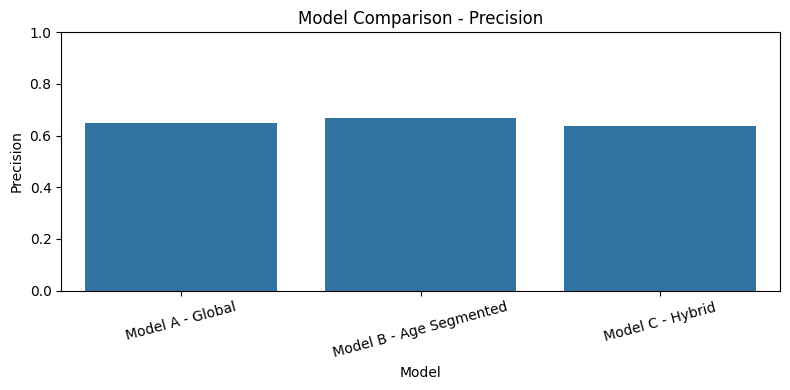

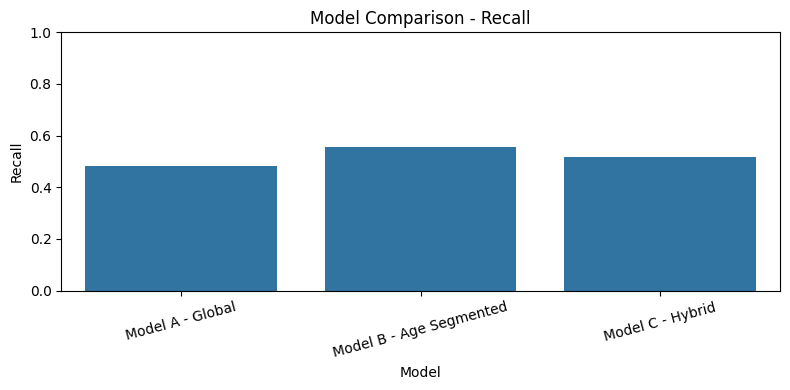

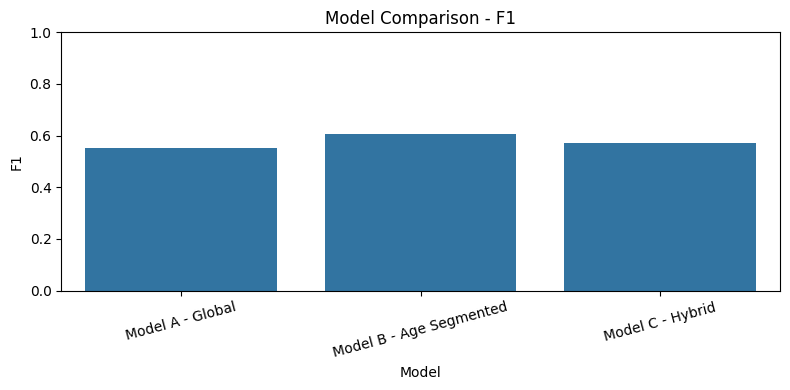

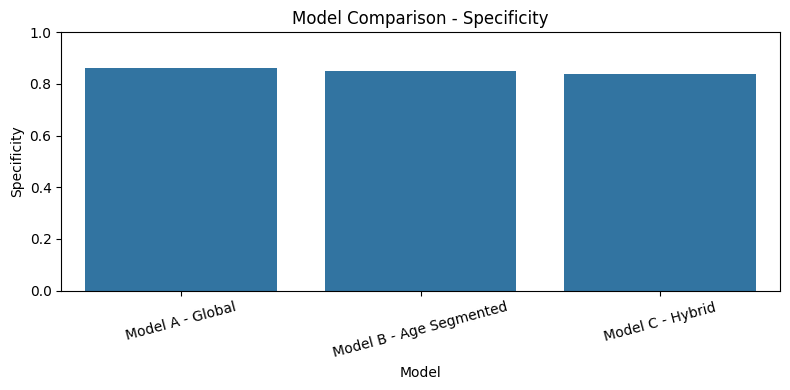

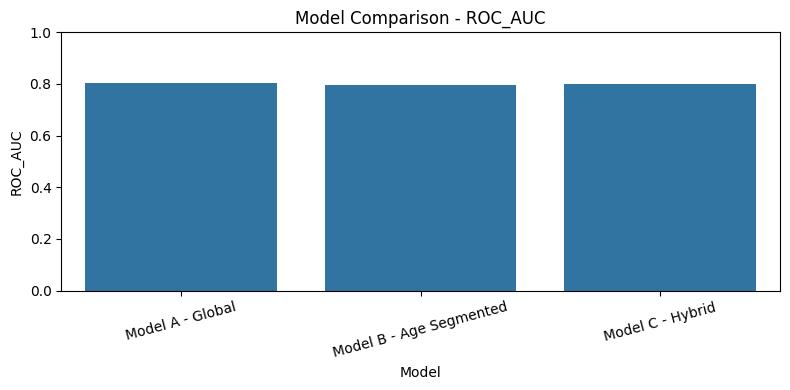

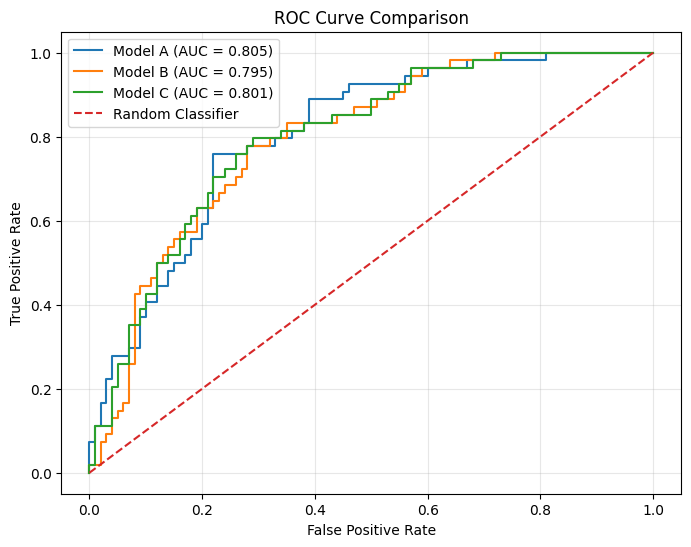


Model A - Global
              precision    recall  f1-score   support

Non-Diabetic       0.75      0.86      0.80       100
    Diabetic       0.65      0.48      0.55        54

    accuracy                           0.73       154
   macro avg       0.70      0.67      0.68       154
weighted avg       0.72      0.73      0.72       154


Model B - Age Segmented
              precision    recall  f1-score   support

Non-Diabetic       0.78      0.85      0.81       100
    Diabetic       0.67      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.70      0.71       154
weighted avg       0.74      0.75      0.74       154


Model C - Hybrid
              precision    recall  f1-score   support

Non-Diabetic       0.76      0.84      0.80       100
    Diabetic       0.64      0.52      0.57        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.69       154
weighted avg 

,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC
Model A - Global,0.7752,0.7639,0.5140,0.6145,0.9150,0.8198
Model B - Age Segmented,0.7752,0.7043,0.6121,0.6550,0.8625,0.8156
Model C - Hybrid,0.7801,0.7423,0.5654,0.6419,0.8950,0.8235



Final test results:


,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC
Model A - Global,0.7273,0.6500,0.4815,0.5532,0.86,0.8046
Model B - Age Segmented,0.7468,0.6667,0.5556,0.6061,0.85,0.7952
Model C - Hybrid,0.7273,0.6364,0.5185,0.5714,0.84,0.8009



Overfitting comparison:


,Train Accuracy,Test Accuracy,Train F1,Test F1,Train ROC_AUC,Test ROC_AUC,Accuracy Gap,F1 Gap
Model A - Global,0.7948,0.7273,0.6595,0.5532,0.8835,0.8046,0.0675,0.1063
Model B - Age Segmented,0.8420,0.7468,0.7506,0.6061,0.9229,0.7952,0.0953,0.1446
Model C - Hybrid,0.8208,0.7273,0.7105,0.5714,0.9104,0.8009,0.0936,0.1391



Models available:
Model A: model_A
Model B: model_B
Model C: Hybrid probability fusion

Research experiment completed successfully!


In [8]:

# ============================================================
# AGE-SEGMENTED BAGGING FOR DIABETES PREDICTION
# PIMA INDIANS DIABETES DATASET
#
# MODEL A: GLOBAL BAGGING
# MODEL B: AGE-SEGMENTED BAGGING
# MODEL C: HYBRID GLOBAL + LOCAL BAGGING
#
# Includes:
# 1. Data loading
# 2. Data preprocessing
# 3. Median imputation
# 4. Age segmentation
# 5. Five-fold cross-validation
# 6. Model training
# 7. Hybrid probability fusion
# 8. Evaluation
# 9. Overfitting analysis
# 10. Visualizations
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully!")


# ============================================================
# 2. LOAD PIMA DATASET
# ============================================================

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(url, names=columns)

print("\nDataset shape:", df.shape)

display(df.head())

print("\nOutcome distribution:")
print(df["Outcome"].value_counts())


# ============================================================
# 3. DATA CLEANING
# ============================================================

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("\nMissing values:")
print(df.isnull().sum())


# ============================================================
# 4. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop("Outcome", axis=1)
y = df["Outcome"]


# ============================================================
# 5. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)


# ============================================================
# 6. OVERALL TRAINING MEDIAN IMPUTATION
# ============================================================

# Calculate medians using training data only
training_medians = X_train.median()

# Apply same medians to train and test
X_train_imputed = X_train.fillna(training_medians)
X_test_imputed = X_test.fillna(training_medians)

print("\nTraining missing values:",
      X_train_imputed.isnull().sum().sum())

print("Testing missing values:",
      X_test_imputed.isnull().sum().sum())


# ============================================================
# 7. AGE SEGMENTATION
# ============================================================

age_bins = [0, 30, 40, 50, np.inf]

age_labels = [
    "Age_21_30",
    "Age_31_40",
    "Age_41_50",
    "Age_51_plus"
]

# Assign age groups
train_groups = pd.cut(
    X_train["Age"],
    bins=age_bins,
    labels=age_labels
)

test_groups = pd.cut(
    X_test["Age"],
    bins=age_bins,
    labels=age_labels
)

print("\nTraining age distribution:")
print(train_groups.value_counts().sort_index())

print("\nTesting age distribution:")
print(test_groups.value_counts().sort_index())


# ============================================================
# 8. AGE GROUP CLASS DISTRIBUTION
# ============================================================

train_analysis = X_train_imputed.copy()
train_analysis["Age_Group"] = train_groups
train_analysis["Outcome"] = y_train

age_distribution = pd.crosstab(
    train_analysis["Age_Group"],
    train_analysis["Outcome"]
)

age_distribution.columns = [
    "Non_Diabetic",
    "Diabetic"
]

print("\nAge group distribution:")
display(age_distribution)


# ============================================================
# 9. VISUALIZE AGE GROUPS
# ============================================================

plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_analysis,
    x="Age_Group",
    hue="Outcome"
)

plt.title("Age Group Diabetes Distribution")
plt.xlabel("Age Group")
plt.ylabel("Patient Count")
plt.xticks(rotation=15)
plt.show()


# ============================================================
# 10. DEFINE BAGGING MODEL
# ============================================================

def create_bagging_model():

    base_tree = DecisionTreeClassifier(
        max_depth=3,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    )

    bagging = BaggingClassifier(
        estimator=base_tree,
        n_estimators=50,
        max_samples=0.80,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("bagging", bagging)
    ])

    return model


print("\nBagging configuration ready!")


# ============================================================
# 11. EVALUATION FUNCTION
# ============================================================

def evaluate_predictions(y_true, probabilities):

    predictions = (probabilities >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    return {
        "Accuracy": accuracy_score(y_true, predictions),

        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),

        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),

        "Specificity": specificity,

        "ROC_AUC": roc_auc_score(
            y_true, probabilities
        )
    }


# ============================================================
# 12. FIVE-FOLD STRATIFIED CROSS VALIDATION
# ============================================================

N_SPLITS = 5

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

X_cv = X_train.reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)

groups_cv = train_groups.reset_index(drop=True)

# Out-of-fold predictions
oof_A = np.zeros(len(X_cv))
oof_B = np.zeros(len(X_cv))
oof_C = np.zeros(len(X_cv))

# Store fold-wise metrics
fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_cv, y_cv), 1
):

    print(f"\n========== FOLD {fold} ==========")

    X_fold_train = X_cv.iloc[train_idx]
    y_fold_train = y_cv.iloc[train_idx]

    X_fold_val = X_cv.iloc[val_idx]

    fold_train_groups = groups_cv.iloc[train_idx]
    fold_val_groups = groups_cv.iloc[val_idx]

    # --------------------------------------------------------
    # MODEL A: GLOBAL BAGGING
    # --------------------------------------------------------

    global_model = create_bagging_model()

    global_model.fit(
        X_fold_train,
        y_fold_train
    )

    global_probs = global_model.predict_proba(
        X_fold_val
    )[:, 1]

    oof_A[val_idx] = global_probs

    # --------------------------------------------------------
    # MODEL B: AGE-SEGMENTED BAGGING
    # --------------------------------------------------------

    local_probs = np.zeros(len(val_idx))

    for group in age_labels:

        train_mask = (
            fold_train_groups == group
        ).to_numpy()

        val_mask = (
            fold_val_groups == group
        ).to_numpy()

        X_local_train = X_fold_train.iloc[
            np.where(train_mask)[0]
        ]

        y_local_train = y_fold_train.iloc[
            np.where(train_mask)[0]
        ]

        X_local_val = X_fold_val.iloc[
            np.where(val_mask)[0]
        ]

        if len(X_local_val) == 0:
            continue

        if y_local_train.nunique() < 2:
            raise ValueError(
                f"Only one class in {group}, fold {fold}"
            )

        local_model = create_bagging_model()

        local_model.fit(
            X_local_train,
            y_local_train
        )

        local_probs[val_mask] = (
            local_model.predict_proba(
                X_local_val
            )[:, 1]
        )

    oof_B[val_idx] = local_probs

    # --------------------------------------------------------
    # MODEL C: HYBRID FUSION
    # --------------------------------------------------------

    hybrid_probs = (
        0.50 * global_probs +
        0.50 * local_probs
    )

    oof_C[val_idx] = hybrid_probs

    # --------------------------------------------------------
    # FOLD EVALUATION
    # --------------------------------------------------------

    for model_name, probs in [
        ("Model A", global_probs),
        ("Model B", local_probs),
        ("Model C", hybrid_probs)
    ]:

        metrics = evaluate_predictions(
            y_cv.iloc[val_idx],
            probs
        )

        metrics["Fold"] = fold
        metrics["Model"] = model_name

        fold_results.append(metrics)

    print("Fold completed!")


print("\nAll cross-validation folds completed!")


# ============================================================
# 13. CROSS VALIDATION RESULTS
# ============================================================

fold_df = pd.DataFrame(fold_results)

print("\nFOLD-WISE PERFORMANCE:")
display(
    fold_df.pivot(
        index="Fold",
        columns="Model",
        values="F1"
    ).round(4)
)

cv_summary = fold_df.groupby("Model").agg({
    "Accuracy": ["mean", "std"],
    "Precision": ["mean", "std"],
    "Recall": ["mean", "std"],
    "F1": ["mean", "std"],
    "Specificity": ["mean", "std"],
    "ROC_AUC": ["mean", "std"]
})

print("\nCROSS VALIDATION SUMMARY:")
display(cv_summary.round(4))


# ============================================================
# 14. OOF PERFORMANCE COMPARISON
# ============================================================

oof_results = pd.DataFrame({
    "Model A - Global": evaluate_predictions(y_cv, oof_A),
    "Model B - Age Segmented": evaluate_predictions(y_cv, oof_B),
    "Model C - Hybrid": evaluate_predictions(y_cv, oof_C)
}).T

print("\nOUT-OF-FOLD PERFORMANCE:")
display(oof_results.round(4))


# ============================================================
# 15. FINAL MODEL A: GLOBAL BAGGING
# ============================================================

model_A = create_bagging_model()

model_A.fit(
    X_train,
    y_train
)

print("\nModel A trained successfully!")


# ============================================================
# 16. FINAL MODEL B: AGE-SEGMENTED BAGGING
# ============================================================

model_B = {}

for group in age_labels:

    mask = (train_groups == group).to_numpy()

    X_group = X_train.iloc[
        np.where(mask)[0]
    ]

    y_group = y_train.iloc[
        np.where(mask)[0]
    ]

    model = create_bagging_model()

    model.fit(
        X_group,
        y_group
    )

    model_B[group] = model

    print(group, "trained successfully!")


# ============================================================
# 17. FINAL MODEL A TEST PREDICTIONS
# ============================================================

prob_A = model_A.predict_proba(
    X_test
)[:, 1]


# ============================================================
# 18. FINAL MODEL B TEST PREDICTIONS
# ============================================================

prob_B = np.zeros(len(X_test))

for group in age_labels:

    mask = (test_groups == group).to_numpy()

    if mask.sum() == 0:
        continue

    X_group_test = X_test.iloc[
        np.where(mask)[0]
    ]

    local_model = model_B[group]

    prob_B[mask] = local_model.predict_proba(
        X_group_test
    )[:, 1]


# ============================================================
# 19. MODEL C: HYBRID FUSION
# ============================================================

prob_C = (
    0.50 * prob_A +
    0.50 * prob_B
)

print("\nAll test predictions generated!")


# ============================================================
# 20. FINAL TEST PERFORMANCE
# ============================================================

final_results = pd.DataFrame({

    "Model A - Global": evaluate_predictions(
        y_test, prob_A
    ),

    "Model B - Age Segmented": evaluate_predictions(
        y_test, prob_B
    ),

    "Model C - Hybrid": evaluate_predictions(
        y_test, prob_C
    )

}).T

print("\n========== FINAL TEST RESULTS ==========")

display(final_results.round(4))


# ============================================================
# 21. TRAINING PERFORMANCE FOR OVERFITTING ANALYSIS
# ============================================================

# Model A training probabilities
train_prob_A = model_A.predict_proba(
    X_train
)[:, 1]


# Model B training probabilities
train_prob_B = np.zeros(len(X_train))

for group in age_labels:

    mask = (train_groups == group).to_numpy()

    X_group_train = X_train.iloc[
        np.where(mask)[0]
    ]

    train_prob_B[mask] = model_B[group].predict_proba(
        X_group_train
    )[:, 1]


# Model C training probabilities
train_prob_C = (
    0.50 * train_prob_A +
    0.50 * train_prob_B
)


train_results = pd.DataFrame({

    "Model A - Global": evaluate_predictions(
        y_train, train_prob_A
    ),

    "Model B - Age Segmented": evaluate_predictions(
        y_train, train_prob_B
    ),

    "Model C - Hybrid": evaluate_predictions(
        y_train, train_prob_C
    )

}).T

print("\n========== TRAINING PERFORMANCE ==========")

display(train_results.round(4))


# ============================================================
# 22. TRAINING VS TEST PERFORMANCE
# ============================================================

overfit_comparison = pd.DataFrame({
    "Train Accuracy": train_results["Accuracy"],
    "Test Accuracy": final_results["Accuracy"],

    "Train F1": train_results["F1"],
    "Test F1": final_results["F1"],

    "Train ROC_AUC": train_results["ROC_AUC"],
    "Test ROC_AUC": final_results["ROC_AUC"]
})

overfit_comparison["Accuracy Gap"] = (
    overfit_comparison["Train Accuracy"] -
    overfit_comparison["Test Accuracy"]
)

overfit_comparison["F1 Gap"] = (
    overfit_comparison["Train F1"] -
    overfit_comparison["Test F1"]
)

print("\n========== OVERFITTING ANALYSIS ==========")

display(overfit_comparison.round(4))


# ============================================================
# 23. CONFUSION MATRICES
# ============================================================

pred_A = (prob_A >= 0.50).astype(int)
pred_B = (prob_B >= 0.50).astype(int)
pred_C = (prob_C >= 0.50).astype(int)

predictions = {
    "Model A - Global": pred_A,
    "Model B - Age Segmented": pred_B,
    "Model C - Hybrid": pred_C
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

for ax, (name, pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


# ============================================================
# 24. PERFORMANCE VISUALIZATION
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Specificity",
    "ROC_AUC"
]

for metric in metrics:

    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=final_results.index,
        y=final_results[metric]
    )

    plt.title(f"Model Comparison - {metric}")

    plt.ylabel(metric)
    plt.xlabel("Model")

    plt.ylim(0, 1)
    plt.xticks(rotation=15)

    plt.tight_layout()
    plt.show()


# ============================================================
# 25. ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Model A", prob_A),
    ("Model B", prob_B),
    ("Model C", prob_C)
]:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 26. CLASSIFICATION REPORTS
# ============================================================

for name, predictions_value in predictions.items():

    print("\n================================")
    print(name)
    print("================================")

    print(
        classification_report(
            y_test,
            predictions_value,
            target_names=[
                "Non-Diabetic",
                "Diabetic"
            ],
            zero_division=0
        )
    )


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print("\n==========================================")
print("EXPERIMENT COMPLETED")
print("==========================================")

print("\nCross-validation OOF results:")
display(oof_results.round(4))

print("\nFinal test results:")
display(final_results.round(4))

print("\nOverfitting comparison:")
display(overfit_comparison.round(4))

print("\nModels available:")
print("Model A: model_A")
print("Model B: model_B")
print("Model C: Hybrid probability fusion")

print("\nResearch experiment completed successfully!")
